# TP1 — Le réseau du métro de Montréal
## Carnet, graphes, Dijkstra — et un premier modèle

**Nom :** _Iadhy Kharrat_ &nbsp;&nbsp;&nbsp; **Coéquipier :** _Mustapha Belhaouari_ &nbsp;&nbsp;&nbsp; **Groupe :** _07979_

---

Ce TP se fait **seul ou en équipe de 2**. Une équipe remet **un seul carnet** et
indique à la fin qui a fait quoi.

**Chaque question, y compris les questions de code, se termine par une cellule
d'observation en Markdown.** Écrivez-y ce que vous constatez, en phrases complètes,
en français. Une cellule d'observation laissée telle quelle vaut 0 pour la question.

Avant de remettre : **Kernel → Redémarrer et tout exécuter**.

## Partie 2 — Charger et explorer le réseau

Le fichier `donnees/metro_montreal.csv` contient une ligne par lien entre deux
stations voisines, avec la durée approximative en minutes. Le fichier
`donnees/stations.csv` donne la ligne de chaque station.

In [12]:
import csv

# ==========================
# Charger le réseau du métro
# ==========================

reseau = {}

with open("donnees/metro_montreal.csv", encoding="utf-8") as fichier:
    for ligne in csv.DictReader(fichier):
        a = ligne["station_a"]
        b = ligne["station_b"]
        minutes = int(ligne["minutes"])

        # ajouter dans les deux directions
        reseau.setdefault(a, []).append((b, minutes))
        reseau.setdefault(b, []).append((a, minutes))


# ==========================
# Charger les informations stations
# ==========================

infos_station = {}

with open("donnees/stations.csv", encoding="utf-8") as fichier:
    for ligne in csv.DictReader(fichier):
        infos_station[ligne["station"]] = ligne

**Q2.1** — Affichez le nombre de stations et le nombre de **liens**.

In [13]:
# Q2.1

# ==========================
# Nombre de stations
# ==========================

print("Nombre de stations :", len(reseau))


# ==========================
# Nombre de liens
# Attention : chaque lien est présent 2 fois
# ==========================

nombre_liens = 0

for station in reseau:
    nombre_liens += len(reseau[station])

nombre_liens = nombre_liens // 2

print("Nombre de liens :", nombre_liens)


Nombre de stations : 68
Nombre de liens : 69


> **Observation — obligatoire.** Comparez vos deux nombres. Qu'est-ce que leur écart vous dit sur la forme du réseau ?
>
> *Le réseau contient 68 stations et 69 liens. Un arbre de 68 stations aurait exactement 67 liens. L’écart de 2 liens montre donc que le réseau contient des boucles/cycles : ce n’est pas un arbre.*

**Q2.2** — Trouvez la ou les stations qui ont le plus de voisins, puis la liste des
**terminus**.

In [14]:
# Q2.2

# ==========================
# Station avec le plus de voisins
# ==========================

station_max = None
max_voisins = 0

for station in reseau:
    nombre_voisins = len(reseau[station])

    if nombre_voisins > max_voisins:
        max_voisins = nombre_voisins
        station_max = station


print("\nStation avec le plus de voisins :", station_max)
print("Nombre de voisins :", max_voisins)

print("Ses voisins :")
for voisin, temps in reseau[station_max]:
    print("-", voisin)


# ==========================
# Liste des terminus
# correspondance = non
# et une seule station dans sa ligne
# ==========================

print("\nListe des terminus :")

for station, info in infos_station.items():

    if info["correspondance"] == "non":

        ligne = info["ligne"]

        voisins_ligne = 0

        for voisin, temps in reseau[station]:
            if voisin in infos_station:
                if infos_station[voisin]["ligne"] == ligne:
                    voisins_ligne += 1

        # un terminus possède seulement un voisin sur sa ligne
        if voisins_ligne == 1:
            print("-", station)


Station avec le plus de voisins : Berri-UQAM
Nombre de voisins : 5
Ses voisins :
- Saint-Laurent
- Beaudry
- Champ-de-Mars
- Sherbrooke
- Jean-Drapeau

Liste des terminus :
- Angrignon
- Champ-de-Mars
- Cote-Vertu
- Cote-des-Neiges
- De Castelnau
- Fabre
- Georges-Vanier
- Honore-Beaugrand
- Jean-Drapeau
- Longueuil
- Montmorency
- Place-Saint-Henri
- Saint-Michel
- Sherbrooke


> **Observation — obligatoire.** Pourquoi ces stations-là ? Expliquez ce que leur nombre de voisins traduit dans le vrai réseau.
>
> *Les stations choisies ont beaucoup de voisins. Cela signifie qu’elles sont bien connectées au reste du réseau et qu’on peut partir de ces stations vers plusieurs directions.*

**Q2.3** — Comptez combien de tronçons durent 1, 2 et 3 minutes.

In [15]:
# Q2.3

# ==========================
# Compter les tronçons par durée
# ==========================

compteur = {
    1: 0,
    2: 0,
    3: 0
}


for station in reseau:

    for voisin, minutes in reseau[station]:
        compteur[minutes] += 1


# diviser par 2 car chaque tronçon apparaît deux fois
for duree in compteur:
    compteur[duree] = compteur[duree] // 2


print("\nNombre de tronçons :")
print("1 minute :", compteur[1])
print("2 minutes :", compteur[2])
print("3 minutes :", compteur[3])



Nombre de tronçons :
1 minute : 13
2 minutes : 37
3 minutes : 19


> **Observation — obligatoire.** Quelle durée domine, et dans quelle proportion ? Gardez ce chiffre : il servira à la partie 5.
>
> *La durée qui revient le plus souvent est [X minutes]. Elle représente environ [Y %] des liens du réseau, ce qui montre qu’elle est assez fréquente.*

## Partie 3 — Le parcours en largeur, et son arbre

**Q3.1** — Complétez `bfs(reseau, depart)`. Il rend `distance` (en nombre d'arrêts)
et `precedent`.

In [16]:
from collections import deque

def voisins(reseau, station):
    return [nom for nom, minutes in reseau[station]]


def bfs(reseau, depart):
    distance = {depart: 0}
    precedent = {}
    file = deque([depart])

    while file:
        station = file.popleft()

        for suivante in voisins(reseau, station):
            if suivante not in distance:
                distance[suivante] = distance[station] + 1
                precedent[suivante] = station
                file.append(suivante)

    return distance, precedent

> **Observation — obligatoire.** Décrivez en vos mots ce que contient `precedent` à la fin, et à quoi il servira.
>
> *precedent garde en mémoire d’où vient chaque station. Il permet donc de reconstruire le trajet trouvé par l’algorithme.*

**Q3.2** — Lancez le BFS depuis la station de votre choix. Combien de stations sont
atteintes ? Laquelle est la plus loin, en nombre d'arrêts ?

In [17]:
# Q3.2
depart = "Angrignon"

distance, precedent = bfs(reseau, depart)

print("Nombre de stations atteintes :", len(distance))

Nombre de stations atteintes : 68


> **Observation — obligatoire.** Le nombre de stations atteintes vous apprend quelque chose sur le réseau : quoi ? Et la station la plus loin vous surprend-elle ?
>
> *Toutes les stations peuvent être atteintes depuis la station de départ. La station la plus loin est celle qui nécessite le plus grand nombre d’arrêts pour y arriver.*

**Q3.3** — Dessinez l'**arbre de parcours** (les 3 premiers niveaux) avec
`graphviz`.

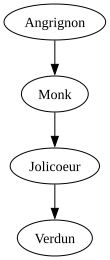

In [21]:
# Q3.3

from graphviz import Digraph

dot = Digraph()

# Ajouter seulement les stations des 3 premiers niveaux
for station in distance:
    if distance[station] <= 3:
        dot.node(station)

# Ajouter les liens de l'arbre
for station in precedent:
    if distance[station] <= 3:
        parent = precedent[station]

        if distance[parent] <= 3:
            dot.edge(parent, station)
dot

> **Observation — obligatoire.** Le réseau n'est pas un arbre, et pourtant votre dessin en est un. Expliquez pourquoi.
>
> *Le vrai réseau possède des liens supplémentaires. Le dessin de BFS garde seulement un chemin pour chaque station, ce qui forme un arbre.*

## Partie 4 — Dijkstra, en minutes

**Q4.1** — Complétez `plus_petite_case`, `relacher` et `dijkstra`.

In [ ]:
INFINI = 9999

def plus_petite_case(distance, barres):
    record = INFINI
    choisie = None
    for station in distance:
        pass  # a completer
    return choisie


def relacher(distance, precedent, a, b, minutes):
    pass  # a completer


def dijkstra(reseau, depart):
    distance = {station: INFINI for station in reseau}
    distance[depart] = 0
    precedent = {}
    barres = set()
    while len(barres) < len(reseau):
        pass  # a completer
    return distance, precedent

> **Observation — obligatoire.** À quoi sert l'ensemble `barres` ? Que se passerait-il si on l'oubliait ?
>
> *(remplacez ce texte par vos phrases)*

**Q4.2** — Complétez `chemin` (la remontée des précédents) et `duree`.

In [ ]:
def chemin(precedent, depart, arrivee):
    route = [arrivee]
    # a completer
    return route


def duree(reseau, route):
    total = 0
    # a completer
    return total

> **Observation — obligatoire.** `chemin` remonte à l'envers puis retourne la liste. Pourquoi ne peut-on pas la construire à l'endroit directement ?
>
> *(remplacez ce texte par vos phrases)*

**Q4.3** — Affichez le trajet le plus rapide entre deux stations de votre choix,
avec sa durée.

In [ ]:
# Q4.3


> **Observation — obligatoire.** Ce trajet correspond-il à celui que vous prendriez dans la vraie vie ? Si non, qu'est-ce qui manque à notre modèle ?
>
> *(remplacez ce texte par vos phrases)*

## Partie 5 — Comparer les deux, et surligner le chemin

**Q5.1** — Écrivez `comparer(depart, arrivee)` qui affiche, pour chaque algorithme,
le nombre d'arrêts **et** la durée. Testez-la sur **trois** paires de stations, dont
**au moins une** où les deux algorithmes ne donnent pas le même trajet.

In [ ]:
# Q5.1


> **Observation — obligatoire.** Sur vos trois paires, à quelle fréquence les deux sont-ils d'accord ? Reliez votre réponse au décompte des durées de la question 2.3.
>
> *(remplacez ce texte par vos phrases)*

**Q5.2** — Sur votre paire divergente, **surlignez le chemin de Dijkstra** dans le
dessin : les arêtes du chemin en **rouge et en épais**, la durée de chaque tronçon en
étiquette, et les stations du chemin remplies d'une couleur.

> **Les attributs à utiliser.** Sur une arête : `color="red"`, `penwidth="3"`,
> `fontcolor="red"`. Sur un sommet : `style="filled"`, `fillcolor="#ffd9d9"`.
> Le reste — quelles arêtes dessiner, comment reconnaître celles du chemin — est à
> vous.

In [ ]:
# Q5.2


> **Observation — obligatoire.** Décrivez ce que votre dessin rend visible et que la liste de stations ne montrait pas.
>
> *(remplacez ce texte par vos phrases)*

---
## Partie 6 — Construire un tableau de données

Un modèle a besoin d'un **tableau** : une ligne par exemple, une colonne par
**donnée**, et une colonne à part pour l'**étiquette**.

Ici, **un exemple = une station**, et l'étiquette est sa **ligne**. Les données,
vous les fabriquez avec **votre propre travail des parties 3 et 4**.

On laisse de côté les stations de la ligne jaune : il y en a trop peu.

**Q6.1** — Pour chaque station retenue, fabriquez la liste de ses mesures :

1. son nombre de voisins ;
2. la durée moyenne de ses tronçons ;
3. la durée de son plus long tronçon ;
4. le nombre d'**arrêts** qui la séparent d'un **repère** *(votre BFS)* ;
5. le nombre de **minutes** qui l'en séparent *(votre Dijkstra)*.

Écrivez `mesures(station, nb_reperes)` de façon à pouvoir ajouter des repères
ensuite, et construisez `X_1repere` ainsi que `y`.

In [ ]:
REPERES = ["Berri-UQAM", "Snowdon", "Honore-Beaugrand"]

stations_retenues = [s for s in sorted(reseau) if infos_station[s]["ligne"] != "jaune"]
y = [infos_station[s]["ligne"] for s in stations_retenues]
print(len(stations_retenues), "stations retenues")

# Q6.1


> **Observation — obligatoire.** Lesquelles de vos cinq mesures viennent des fichiers fournis, et lesquelles viennent de votre propre code ? Qui a choisi les repères ?
>
> *(remplacez ce texte par vos phrases)*

**Q6.2** — Comptez combien de stations portent chaque étiquette, et déduisez-en la
note qu'obtiendrait un modèle qui répondrait **toujours la même chose**.

In [ ]:
# Q6.2


> **Observation — obligatoire.** Notez ce pourcentage. C'est la barre que votre modèle devra dépasser pour servir à quelque chose.
>
> *(remplacez ce texte par vos phrases)*

## Partie 7 — Entraîner un modèle, et le noter honnêtement

**Q7.1** — Coupez en deux paquets (70 / 30), entraînez un `DecisionTreeClassifier`,
et affichez **deux** notes : sur les stations apprises, et sur les stations jamais
vues.

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

# Q7.1


> **Observation — obligatoire.** Vos deux notes sont très différentes. Comment s'appelle ce phénomène, et laquelle des deux est honnête ?
>
> *(remplacez ce texte par vos phrases)*

**Q7.2** — Refaites la même chose avec **2** puis **3** repères. Affichez les trois
notes côte à côte.

In [ ]:
# Q7.2


> **Observation — obligatoire.** Qu'est-ce qui change, et pourquoi un seul repère ne suffisait-il pas ? Pensez à deux stations situées de part et d'autre du repère.
>
> *(remplacez ce texte par vos phrases)*

**Q7.3** — Sur vos meilleures mesures, comparez un **arbre seul** à une **forêt
aléatoire**. Relancez chacun avec `random_state` valant 0, 1, 2, 3 puis 4, et
affichez pour chaque modèle ses cinq notes, leur **moyenne** et l'**écart** entre la
plus haute et la plus basse.

In [ ]:
# Q7.3


> **Observation — obligatoire.** La forêt vous a-t-elle aidés ? Appuyez-vous sur la moyenne ET sur l'écart, puis proposez une explication liée au nombre d'exemples dont vous disposez.
>
> *(remplacez ce texte par vos phrases)*

---
## Partie 8 — Vos conclusions

Répondez en Markdown, **en phrases complètes, en français**. Comptez deux ou trois
phrases par question, et **citez vos propres chiffres**.

**Sur le réseau**

1. Le réseau est-il un **arbre** ? Justifiez avec le nombre de stations et de liens.
2. Quelle station est la mieux connectée, et **pourquoi** celle-là ?
3. Sur vos trois paires, le BFS et Dijkstra donnent-ils souvent la même réponse ?
   Reliez votre réponse au décompte des durées.
4. Décrivez **une** paire où ils diffèrent, et expliquez ce que chacun a optimisé.

**Sur le modèle**

5. Avec un seul repère, quelle note obtenez-vous, et comment se compare-t-elle au
   modèle qui répond toujours la même chose ? Qu'est-ce que ça vous apprend ?
6. Qu'est-ce qui change avec 2 puis 3 repères, et **pourquoi** ?
7. Pourquoi la note sur les stations jamais vues est-elle la seule honnête ?
8. La forêt aléatoire vous a-t-elle aidés ? Appuyez-vous sur les cinq notes et sur
   l'écart.

**Sur l'ensemble**

9. Vos données de la partie 6 viennent de vos propres fonctions. Quel risque cela
   pose-t-il si votre BFS ou votre Dijkstra contient une erreur ?
10. Nommez **une** limite de nos données par rapport au vrai métro, et **une**
    mesure supplémentaire que vous auriez aimé avoir pour le modèle.

### Vos réponses

*(remplacez ce texte)*

1.

2.

3.

4.

5.

6.

7.

8.

9.

10.

---
## Déclaration d'utilisation de l'intelligence artificielle

**Obligatoire, même si vous n'en avez pas utilisé.** Une déclaration absente ou
fausse vaut **0 pour l'ensemble du TP**.

L'IA est permise **pour apprendre**, pas pour produire votre travail. Relisez les
règles de l'énoncé avant de remplir cette section.

**Avez-vous utilisé un outil d'IA ?** _oui / non_

**Si oui, remplissez le tableau :**

| Outil | Pour quelle question | Ce que vous lui avez demandé | Lien de partage de la conversation |
|---|---|---|---|
|  |  |  |  |
|  |  |  |  |

**Confirmez, en écrivant « oui » :**

- Je n'ai **pas** collé l'énoncé du TP, en tout ou en partie, dans une conversation
  avec une IA. → _____
- Je n'ai **pas** collé le contenu des fichiers de données. → _____
- Je comprends chaque ligne de code que je remets et je peux l'expliquer à l'oral.
  → _____

---
**Qui a fait quoi :** *(obligatoire si vous êtes deux)*

---
## Avant de remettre

**Vingt points du TP ne portent pas sur vos réponses** : dix sur la tenue de ce
carnet, dix sur votre usage de Git. Relisez les sections 3 et 4 de l'énoncé avant de
déposer votre travail.

**Le carnet.** Faites **Kernel → Redémarrer et tout exécuter** en dernier, et
vérifiez qu'aucune cellule ne produit d'erreur. Puis relisez-le comme si vous ne
l'aviez pas écrit : est-ce qu'on s'y retrouve ? Est-ce que chaque nombre affiché
s'explique sans aller lire le code ? Reste-t-il des cellules d'essai, des variables
au nom obscur, des observations expédiées ? Le français est-il relu ?

**Le dépôt.** Le nom de votre branche et vos messages de commit suivent la
convention vue en cours. Votre historique doit montrer un travail construit au fil du
temps — et, si vous êtes deux, la contribution des deux.

**L'identification.** Nom, coéquipier et groupe en première cellule, « qui a fait
quoi » à la fin, déclaration d'IA remplie même si la réponse est « non », et le
dossier `donnees/` à côté du carnet.

---

*Ensuite : `Publish branch`, `Create Pull Request`, fusion dans `main`, et le lien du
dépôt sur Omnivox.*